<a href="https://colab.research.google.com/github/muraiukiha/face-recognition/blob/main/Fisher_faces.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from sklearn.datasets import fetch_olivetti_faces
import numpy as np
from sklearn.datasets import fetch_lfw_people

#lfwの読み込み
lfw = fetch_lfw_people(
    slice_ = (slice(70, 198), slice(61,189)),
    resize = 0.5
)
faces = fetch_olivetti_faces()
print(faces.data.shape)
print(faces.images.shape)
print(faces.target.shape)
print(np.where(faces.target == 3)[0])

(400, 4096)
(400, 64, 64)
(400,)
[30 31 32 33 34 35 36 37 38 39]


In [8]:
rng = np.random.default_rng(42)
train_list = []
test_list = []
for person in range(40):
  indices = np.where( faces.target == person)[0]

  shuffled = rng.permutation(indices)
  train = shuffled[:7]
  test = shuffled[7:]
  train_list.extend(train)
  test_list.extend(test)

print('学習用:',len(train_list))
print('テスト用:',len(test_list))




学習用: 280
テスト用: 120


In [9]:
#データ分割
X_train=[]
X_test = []
Y_train = []
Y_test = []
Y_train = faces.target[train_list]
Y_test = faces.target[test_list]
for id in train_list:
  X_train.append(faces.data[id])

for id in test_list:
  X_test.append(faces.data[id])
X_train = np.array(X_train)
X_test = np.array(X_test)

print(X_train.shape)
print(X_test.shape)



(280, 4096)
(120, 4096)


In [13]:
#PCAの部分
from sklearn.decomposition import PCA
pca = PCA(n_components=240)

pca.fit(X_train)
print(pca.components_.shape)
X_train_pca = pca.transform(X_train)
print(X_train_pca.shape)
X_test_pca = pca.transform(X_test)
print(X_test_pca.shape)
X_lfw_pca = pca.transform(lfw.data)
print(X_lfw_pca.shape)

(240, 4096)
(280, 240)
(120, 240)
(13233, 240)


In [15]:
#LDAの部分
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=39)
lda.fit(X_train_pca,Y_train)
X_train_lda = lda.transform(X_train_pca)
X_test_lda = lda.transform(X_test_pca)
print(X_train_lda.shape)
print(X_test_lda.shape)
X_lfw_lda = lda.transform(X_lfw_pca)
print(X_lfw_lda.shape)


(280, 39)
(120, 39)
(13233, 39)


In [22]:
#ユークリッド距離比較

correct = 0
rejected = 0
misidentified = 0
accepted = 0
threshold = 250
registered_distances = []
unknown_distances = []
for i in range(len(X_test_lda)):
  b = np.array(X_test_lda[i])
  distances = []
  for number in range(len(X_train_lda)):
    a = np.array(X_train_lda[number])
    distance = np.linalg.norm(a-b)
    distances.append(distance)
#print(len(distances))
#最近傍
  nearest_index = np.argmin(distances)
  answer = Y_train[nearest_index]
  if np.min(distances) <= threshold:
    if answer == Y_test[i]:
      correct = correct + 1
    else :
      misidentified += 1
  else :
      rejected += 1
  registered_distances.append(np.min(distances))
for i in range(len(X_lfw_lda)):
  a = np.array(X_lfw_lda[i])
  distances = []
  for number in range(len(X_train_lda)):
    b = np.array(X_train_lda[number])
    distance = np.linalg.norm(a-b)
    distances.append(distance)
  if np.min(distances) <= threshold:
    accepted += 1
  unknown_distances.append(np.min(distances))
accuracy = correct / len(X_test_lda)
FAR = accepted /len(X_lfw_lda) * 100
print('正答率',accuracy*100,'%')
print('FRR',rejected/len(X_test_pca)*100)
print('FAR',FAR,'%')
print(correct+misidentified+rejected)

正答率 55.00000000000001 %
FRR 11.666666666666666
FAR 16.79135494596841 %
120


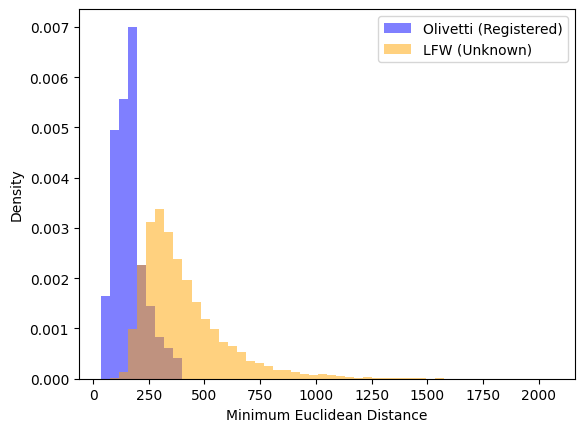

In [21]:
#最短距離のグラフ化
import matplotlib.pyplot as plt
bins = np.linspace(
    min(min(registered_distances), min(unknown_distances)),
    max(max(registered_distances), max(unknown_distances)),
    51
)

plt.hist(registered_distances, bins=bins, density=True,
         alpha=0.5, color='blue', label='Olivetti (Registered)')

plt.hist(unknown_distances, bins=bins, density=True,
         alpha=0.5, color='orange', label='LFW (Unknown)')

plt.xlabel('Minimum Euclidean Distance')
plt.ylabel('Density')
plt.legend()
plt.show()


